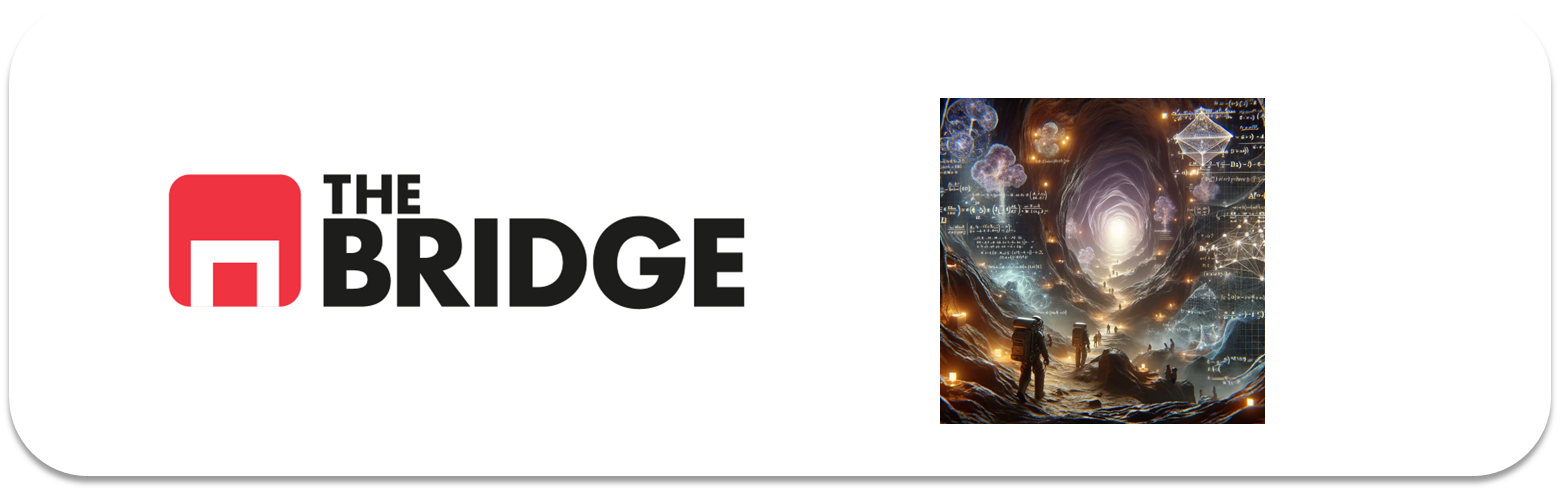

# Tutorial introductorio a Keras

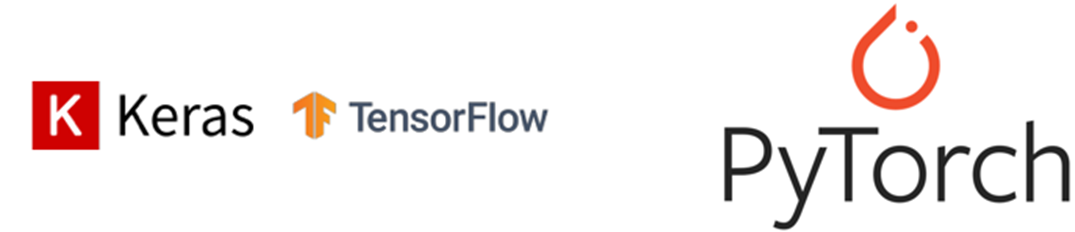

En el mundo del DL en Python hay dos grandes frameworks (es decir librerías que han crecido como para ser algo más que conjuntos de módulos y funciones): TensorFlow (Google) y PyTorch (Meta). Ambos son muy potentes: algo así como un numpy con esteroides más las herramientas para construir y entrenar modelos. Son muy flexibles y tienen muchísimas funcionalidades... pero el precio es el de siempre: son complejos, tienen una curva de aprendizaje alta y exigen manejar con soltura matrices y tensores. Para simplificar la vida del Data Science aparece Keras: una API de alto nivel que nos ofrece DL con un esfuerzo considerablemente menor. Durante años fue parte de TensorFlow (`tf.keras`) y desde Keras 3 es *multi-backend*: el mismo código puede ejecutarse sobre TensorFlow, JAX o PyTorch. Nosotros lo usaremos con TensorFlow por debajo. 

¿Qué vamos a ver nosotros? Un uso introductorio, pero que ya da muchas posibilidades. Si te interesa profundizar, aquí tienes la documentación oficial:

[Documentación](https://keras.io/guides/)

## Conceptos básicos: de la neurona a la red

Antes de abrir Keras, repasemos las piezas con las que vamos a construir.

### La neurona (perceptrón)

Una neurona artificial recibe un vector de entradas $x_1, \dots, x_n$ (nuestras features), multiplica cada una por un **peso** $w_i$, suma un término independiente o **bias** $b$ (el $w_0$ de la imagen, asociado a una entrada constante 1) y aplica al resultado una **función de activación** $f$:

$$\hat{y} = f\left(\sum_{i=1}^{n} w_i x_i + b\right)$$

<img src="./img/perceptron-6168423.jpg" alt="perceptron" width="500"/>

El perceptrón original (Rosenblatt, 1958) usaba como activación una función escalón (step): sale 1 si la suma supera un umbral y 0 si no. Es, en el fondo, un clasificador lineal muy parecido a una regresión logística. Los **pesos y el bias son los parámetros que se aprenden** al entrenar.

### Del perceptrón a la red: el MLP

Una sola neurona sólo puede separar clases con una frontera lineal. Si apilamos neuronas en **capas** obtenemos un **perceptrón multicapa (MLP)** o **red densa**:

* **Capa de entrada**: no calcula nada, son las features.
* **Capas ocultas** (*hidden layers*): cada neurona está conectada con todas las salidas de la capa anterior (por eso se llaman capas *densas* o *fully connected*). Cada capa crea nuevas "pseudo-features" combinando las de la anterior.
* **Capa de salida**: tantas neuronas como valores a predecir (1 en regresión o clasificación binaria, tantas como clases en multiclase).

Para que apilar capas sirva de algo, las activaciones de las capas ocultas tienen que ser **no lineales** (hoy en día casi siempre **ReLU**: $max(0, z)$). Si fueran lineales, toda la red equivaldría a un único modelo lineal. Cuando una red tiene varias capas ocultas hablamos de **Deep Learning**.

### ¿Cómo aprende una red?

1. **Forward pass**: los datos atraviesan la red capa a capa y se obtiene una predicción.
2. **Función de pérdida (loss)**: mide cuánto se equivoca esa predicción (MSE en regresión, *cross-entropy* en clasificación).
3. **Backpropagation**: se calcula el gradiente de la loss respecto a cada peso, propagándolo desde la salida hacia atrás (regla de la cadena).
4. **Descenso de gradiente**: el **optimizador** mueve cada peso un poco en la dirección que reduce la loss. Cuánto se mueve lo controla el **learning rate**.

Este ciclo no se hace con todo el dataset a la vez, sino por **batches** (lotes de, por ejemplo, 32 filas): cada batch produce una actualización de pesos. Una **epoch** es una pasada completa por todo el dataset de entrenamiento. Entrenar una red es repetir el ciclo durante varias epochs.

Todo esto (capas, activaciones, loss, optimizador, batch size, epochs) es lo que vamos a configurar con Keras.

Empezamos importando librerías

In [1]:
import tensorflow as tf
from tensorflow import keras

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

keras.utils.set_random_seed(42) # Semilla para que los resultados sean reproducibles

### Carga de Datos (con train y test split incluido)

Para ver cómo usar Keras y repasar algunos conceptos de DL y la forma de trabajar con él, vamos a crearnos un modelo de clasificación de imágenes con redes densas (o perceptrones multicapa), es decir con capas ocultas totalmente conectadas. Así iremos viendo cómo se trabaja con Keras y sus diferentes opciones. Empecemos con los datos.

Cargamos los datos de mnist, el dataset de números "a mano" más famoso de la esfera del Data Science. Y como todavía no hemos visto las redes que pueden trabajar con las imágenes en 2D, aplanaremos las imágenes, como hemos hecho otras veces: los píxeles de cada imagen se convertirán en un vector de 28x28 = 784 features independientes, que serán las entradas del modelo.

In [2]:
# Cogemos las imágenes de los dígitos así como el conjunto de train y test
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Vemos dimensiones del dataset

In [3]:
'''
60.000 imágenes de 28x28 píxeles
'''
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [4]:
X_train.size

47040000

In [5]:
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

60.000 imágenes de 28x28 píxeles. Vamos a representar una de ellas

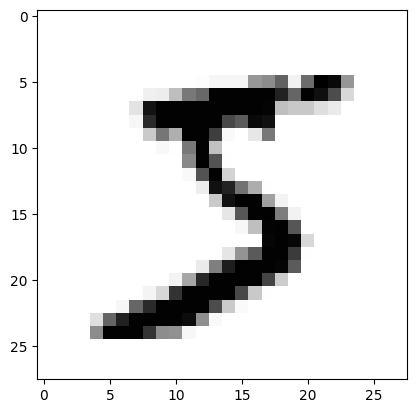

In [6]:
plt.imshow(X_train[0], cmap='Greys');

In [7]:
y_train[0]

5

In [8]:
X_train[25000,12,18]

246

In [9]:
X_train.shape

(60000, 28, 28)

### MiniEDA/Tratamiento de features

Como "buen" miniEDA DL solo vamos a ver el target y a normalizar las features (las redes se entrenan con descenso de gradiente, que es muy sensible a la escala de las features)

In [10]:
pd.Series(y_train).value_counts(normalize = True) # Un detalle interesante: en DL es bastante normal trabajar directamente con arrays de numpy y no con dataframes, más si son imágenes

1    0.112367
7    0.104417
3    0.102183
2    0.099300
9    0.099150
0    0.098717
6    0.098633
8    0.097517
4    0.097367
5    0.090350
Name: proportion, dtype: float64

El dataset está bastante equilibrado (los modelos de DL admiten también el equivalente a class_weight para balancear), aunque hay algo más de ejemplos del 1, el 7 y el 3

#### Escalado

Podríamos usar un MinMaxScaler o un StandardScaler, pero aquí hay una forma más directa: los valores de gris de las imágenes van de 0 a 255, así que para hacer el equivalente a un MinMaxScaler basta con dividir entre 255

In [11]:
# Preprocesamos los datos (son arrays de NumPy).
# Escalamos ya que vamos a usar gradient descent, y le afecta mucho la escala de las features.
# Ejecutar esta celda solo una vez. Si no, reescalará

X_train = X_train.astype("float32") / 255
X_test = X_test.astype("float32") / 255

y_train = y_train.astype("float32")
y_test = y_test.astype("float32")

In [12]:
'''
Comprobamos la normalización
'''
X_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

### ¿Y el Validation_set?

En el tratamiento de modelos de DL lo normal es no usar validación cruzada (en general, porque no solemos comparar muchos modelos alternativos y, sobre todo, porque los entrenamientos son tan pesados que repetirlos k veces sería muy costoso en tiempo). Lo que se suele hacer es tener un dataset de Validación. Como nos han dado train y test ya separados, "cortamos un cacho" del train.

Guardamos datos para validación. Estos datos se usarán durante el entrenamiento. Otra opción es decirle a Keras en la etapa de entrenamiento que reserve un X % de los datos para validar (como argumento del método `fit`).

In [13]:
# Reservamos 10.000 muestras para validación. Entrarán dentro del modelo para validar. No es validación cruzada
X_val = X_train[-10000:]
y_val = y_train[-10000:]

X_train = X_train[:-10000]
y_train = y_train[:-10000]

print(X_val)

[[[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 ...

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]]


In [14]:
pd.Series(y_val).value_counts(True)

7.0    0.1090
1.0    0.1064
3.0    0.1030
8.0    0.1009
0.0    0.0991
2.0    0.0990
4.0    0.0983
6.0    0.0967
9.0    0.0961
5.0    0.0915
Name: proportion, dtype: float64

Además, la proporción de cada clase se mantiene bastante bien (casi como si hubiéramos estratificado).

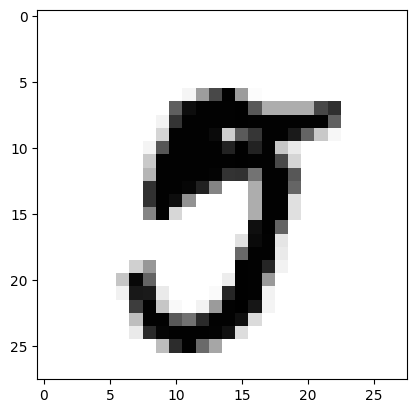

In [15]:
plt.imshow(X_val[1234], cmap='Greys')

In [16]:
y_val[1234]

5.0

***

## DEFINICIÓN/CONSTRUCCIÓN

Para este problema vamos a construir una topología "sencilla": varias capas completamente conectadas, es decir, un MLP o red densa (aunque, a diferencia del perceptrón original, sus neuronas no usarán el escalón como función de activación). Vamos a montar la siguiente red:

<img src="./img/mlp_clasification.png" alt="drawing" width="300"/>

#### Capas de Keras

¿Cómo construimos con Keras? Con *layers*: distintos tipos de capas que se encajan entre sí como piezas de lego. Tendremos capas densas, con sus neuronas y pesos entrenables, pero también capas que hacen otras transformaciones y no se entrenan (como `Flatten`), y capas más complejas que iremos viendo en las siguientes unidades. 

En nuestro caso para implementar una topología sencilla como la anterior aplicada a nuestro problema específico de clasificación de MNIST usaremos las siguientes capas (layers) de Keras:

* **Sequential**: API para iniciar la red neuronal. No cuenta como capa.
* **Input**: indica la forma (*shape*) de cada instancia de entrada, en nuestro caso imágenes de 28x28. No tiene neuronas ni pesos.
* **Flatten**: aplana las imágenes (2D) en un vector 1D de 784 valores, que es lo que necesita una capa densa.
* **Dense**: es una hidden layer. Cada hidden layer se compondrá de `n` neuronas y de una función de activación que se aplicará a todas las neuronas de la capa. La capa de salida también será densa (porque sus unidades o neuronas estarán conectadas a todas las unidades de la capa anterior) pero como es un problema de clasificación multiclase (10 clases), se compondrá de tantas neuronas como clases tengamos (o sea... muy bien, diez unidades o neuronas).



#### Softmax

Un poco más sobre la activación softmax:    

Fórmula:  
<img src="./img/softmax_function.png" alt="drawing" width="150"/>

Función de transferencia:  
<img src="./img/softmax_activation.png" alt="drawing" width="150"/>

Ejemplo de funcionamiento:  
<img src="./img/softmax_example.png" alt="drawing" width="400"/>

$$Softmax(5) = \frac{e^5}{e^5+e^{2.5}+e^{0.5}} = \frac{148.41}{148.41 + 12.18 + 1.65} = 0.91$$

Es una activación un poco especial: no se calcula neurona a neurona por separado, sino que usa las salidas de todas las neuronas de la capa para que el resultado sume 1 (una probabilidad por clase).

A construir...

#### Construcción "apilando"

In [17]:
# Una manera de declarar la red neuronal

# Creamos un modelo secuencial vacío (API Sequential): las capas se ejecutan una detrás de otra
model = keras.models.Sequential()

# Input: forma de cada instancia de entrada (imágenes de 28x28)
model.add(keras.Input(shape=(28,28)))

# Flatten, aplana en un único vector. Es como si hiciese un .reshape(-1, 28*28)
model.add(keras.layers.Flatten())

# Capas de la red. Dense es la capa de neuronas. Necesitamos número de neuronas y activación
# "kernel_initializer" o "bias_initializer": no los usamos, pero servirían para inicializar los pesos de otra manera
model.add(keras.layers.Dense(units = 300, # Número de neuronas de la capa
                             activation='relu'))

model.add(keras.layers.Dense(100,
                             activation='relu'))

# Capa de salida, con tamaño del número de clases
# Multiclase -> softmax. Si es binaria -> 1 neurona con sigmoide
model.add(keras.layers.Dense(10, activation='softmax'))

#### Construcción con listas (secuencias de capas)

In [18]:
# Otra manera de declarar la red neuronal
capas = [
    keras.Input(shape=(28,28)),
    keras.layers.Flatten(),
    keras.layers.Dense(300, activation='relu'),
    keras.layers.Dense(100, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
]
model = keras.models.Sequential(capas)

#### Usando la denominada "Functional API"

La functional API de Keras va encadenando capas como si fueran llamadas de funciones entre sí, es un poco más compleja pero permite topologías mucho más ricas

In [19]:
# Y una forma mediante encadenamiento de funciones (usando lo que se denomina la Functional API)
input_layer = keras.Input(shape = (28,28))
flatten_layer = keras.layers.Flatten()(input_layer)
hidden_1 = keras.layers.Dense(300, activation = "relu")(flatten_layer)
hidden_2 = keras.layers.Dense(100, activation = "relu")(hidden_1)
output = keras.layers.Dense(10, activation = "softmax")(hidden_2)
model = keras.Model(inputs = input_layer, outputs = output)

La functional API me va a permitir construir redes como estas:

<img src="./img/otras_arquitecturas.png" alt="drawing" width="600"/>

Podemos ver las capas, y acceder a sus elementos

In [20]:
# Con la Functional API, la capa 0 es la de Input
print(model.layers[1])
model.layers

<Flatten name=flatten_2, built=True>


[<InputLayer name=input_layer_2, built=True>,
 <Flatten name=flatten_2, built=True>,
 <Dense name=dense_6, built=True>,
 <Dense name=dense_7, built=True>,
 <Dense name=dense_8, built=True>]

Aunque no hayamos entrenado, ya podemos ver los pesos de las capas, porque Keras los inicializa aleatoriamente al construir el modelo (los bias, a 0).

In [21]:
hidden1 = model.layers[2]
weights, biases = hidden1.get_weights()

# 784 features (píxeles de las imágenes) x 300 neuronas
# Los pesos están inicializados aleatoriamente (los bias a cero)
weights.shape

(784, 300)

In [22]:
weights.size

235200

In [23]:
weights[0]

array([ 0.05934983, -0.01557511,  0.06535856, -0.04841957,  0.0146559 ,
        0.07282716,  0.07207912,  0.04567063, -0.02794218, -0.01063228,
        0.04047868,  0.04297978,  0.01013625, -0.04015476,  0.01782211,
       -0.05116828,  0.00926179, -0.03810252,  0.06596619,  0.0165163 ,
       -0.02453706,  0.006686  ,  0.04479699,  0.00151902,  0.04603384,
       -0.00081273, -0.06505005,  0.02286378, -0.06604188,  0.04106998,
       -0.01352591, -0.06932702,  0.04108498,  0.03274021, -0.04091346,
        0.07271384, -0.00777491,  0.06432322, -0.00317378,  0.01288238,
        0.02902367,  0.06818062, -0.05513244, -0.04616619, -0.02352875,
        0.00369978,  0.04565027,  0.05563807,  0.0068458 , -0.03105348,
       -0.04713533, -0.05710553,  0.06118296, -0.05202158, -0.07177539,
       -0.00819815, -0.01253747,  0.0461556 ,  0.02639882, -0.01118708,
       -0.06043262,  0.06624891,  0.00493455, -0.01839841,  0.06375687,
       -0.00071321,  0.01125611,  0.02016212,  0.04725749, -0.06

Y, aunque no esté entrenado, ya podríamos hacer una predicción

In [24]:
model.predict(X_train[1234:1235]) # Espera batches o conjuntos de instancias, por eso hay que dárselo así

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 389ms/step


array([[0.0948511 , 0.13295442, 0.07821159, 0.10505507, 0.10123821,
        0.08668938, 0.10935887, 0.1426812 , 0.09533656, 0.05362358]],
      dtype=float32)

Obtenemos una salida por neurona, es decir, una "probabilidad" por clase. Para saber qué clase predice, nos quedamos con la de mayor probabilidad:

In [25]:
model.predict(X_train[1234:1235])[0].argmax()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


7

Nuestro modelo no entrenado pero inicializado nos da un dígito... ¿y la imagen era?

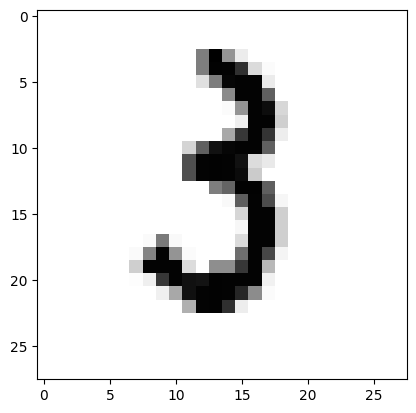

In [26]:
plt.imshow(X_train[1234], cmap = "Greys")

Como los pesos son aleatorios, la predicción es básicamente al azar: si acierta, es pura suerte (1 de cada 10 veces). Para que la red sirva hay que **entrenarla**.

***

#### Inicializadores:  

Al hilo de los pesos que acabamos de ver: cuando construimos una red, sus pesos se inicializan con valores aleatorios distintos. Si todos empezaran igual (por ejemplo, a cero), todas las neuronas de una capa recibirían el mismo gradiente y aprenderían exactamente lo mismo, así que la red no aprendería nada útil. Además, la forma de inicializar afecta al entrenamiento y no vale un aleatorio cualquiera; de hecho, el tipo de inicialización es un hiperparámetro.

O sea:

- Pesos inicializados a cero (o todos iguales) -> todas las neuronas aprenden lo mismo: no hay aprendizaje útil
- Desde siempre se inicializan "aleatoriamente", pero no sólo de forma uniforme (todos los valores con la misma probabilidad), sino que se emplean diferentes distribuciones de probabilidad con parámetros que dependen del número de entradas y salidas de la capa. El objetivo es intentar que las varianzas de las entradas sean similares a las de las salidas y evitar el problema del gradiente que se desvanece ("Vanishing Gradient" problem):  
    *   Glorot initialization (la de Keras por defecto, con distribución uniforme) -> Para capas sin activación o con tanh, sigmoid o softmax (aunque, al ser la de por defecto, se usa :-) para casi todo) [Xavier Glorot & Yoshua Bengio]
    *   He initialization -> Para ReLU, Leaky ReLU, ELU, GELU, Swish, Mish [Kaiming He et al.]
    *   LeCun initialization -> Para SELU [Yann LeCun]
- Es un hiperparámetro

Configuramos el entrenamiento con el método `compile`: optimizador, función de pérdida y métricas.

In [27]:
# Se especifica la configuración del entrenamiento (optimizador, pérdida, métricas):
model.compile(
    # Stochastic gradient descent. El algoritmo para minimizar la loss function
    # Es "estocástico" porque actualiza los pesos con cada batch, no con todo el dataset
    # Podemos modificar el learning rate (0.01 por defecto) mediante el parámetro learning_rate
    optimizer=keras.optimizers.SGD(),  # Optimizer, con parámetros por defecto

    # Loss function to minimize
    # sparse_categorical_crossentropy cuando el target es una única columna con la etiqueta (0, 1, ..., 9)
    # categorical_crossentropy si el target viene en one-hot (una columna por clase)
    # binary_crossentropy si es clasificación binaria (una neurona de salida)
    loss=keras.losses.SparseCategoricalCrossentropy(),

    # List of metrics to monitor
    metrics=[keras.metrics.SparseCategoricalAccuracy()],
)

In [28]:
# Equivalente (... casi, los parámetros del optimizador serán los que tenga por defecto)
model.compile(optimizer="sgd",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

In [29]:
# Summary
# La primera hidden layer tiene 784 entradas x 300 salidas
# Son los 235500 params = 784x300 + 300 (bias)
model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

#### CAPAS

Vayamos construyendo nuestra __lista de capas__:

__Entrenables__:  
__* Dense__ -> Capa completamente conectada a las neuronas de la capa anterior y a la posterior  
    Hiperparámetros asociados:     
        * units: Number of neurons, dimensionality of the output space  
        * activation: Activation function to use. If you don't specify anything, no activation is applied  
        * kernel_initializer: Initializer for the kernel weights matrix.  
        * bias_initializer: Initializer for the bias vector. (Suelen inicializarse a cero)
        * kernel_regularizer: Los clásicos (L1,L2,...)
 
__Funcionales__:       
__* Input__ -> Capa para definir la forma de la entrada (shape) (`keras.Input(shape=...)`)  
__* Flatten__ -> Capa que aplana (convierte su entrada en un vector)

***

### Funciones de activación

Otras funciones de activación interesantes: SELU (una ELU escalada: ≈1.0507·ELU con α≈1.6733) y Swish (también SiLU, o Sigmoid Linear Unit)... No entrar en pánico, vais a usar ReLU, Softmax y no-activation, y en algunos casos (quizás): sigmoid, tanh y las (x)LU (SELU, Swish, etc)

<img src="./img/activation_functions.png" alt="drawing" width="600"/>



#### OPTIMIZADORES

Seguimos completando la lista de hiperparámetros, ahora los asociados al optimizador:  
Tipo de optimizador:  
* __SGD__, Gradient descent "genérico" (se le puede añadir "momento": al actualizar los pesos tiene en cuenta también la dirección de los gradientes anteriores, como una bola que rueda y va cogiendo inercia)
  

* __Adagrad__, Learning rate adaptativo por parámetro: divide el paso de cada peso por la raíz de la suma de sus gradientes al cuadrado acumulados, así los pesos con gradientes grandes avanzan menos (evita irse sólo por las pendientes más inclinadas). Problema: como acumula desde el principio, el learning rate efectivo decae demasiado y el entrenamiento puede frenarse antes de llegar al mínimo.    

* __RMSprop__, Versión de AdaGrad que, en vez de acumular todos los gradientes, usa una media móvil exponencial (considera principalmente los últimos). Mantiene lo bueno de Adagrad sin que el learning rate se apague.    

* __Adam__, _Adaptive Moment Estimation_, combina RMSProp y el uso de momento. Es el rey actual (junto con sus versiones) para grandes cantidades de datos.    

* __AdamW, Nadam, AdaMax__, variantes del anterior. 

Comparativa, donde * es malo y *** bueno (extraído del "Hands-on Machine Learning with...." de Aurélien Géron, 3ª edición)

<img src="./img/Comparativa-optimizadores.png" alt="drawing" width="800"/>

Keras también permite:
__Adadelta__ _(variante de Adagrad)_, __Adafactor__ y __Ftrl__

      
Hiperparámetros Genéricos:
Learning Rate: Coeficiente aplicado al descenso de gradiente, como en otros modelos que ya hemos visto  
Asociados al Gradient Clipping: clipnorm, clipvalue, global_clipnorm

Cada optimizador además puede tener sus propios hiperparámetros (ver: https://keras.io/api/optimizers/)

 




### Funciones de pérdida y métricas
__Función de pérdida__: La función a minimizar durante el entrenamiento (son las mismas que en otros modelos no Deep)  
- Clasificación: En clases Keras -> __BinaryCrossEntropy, CategoricalCrossEntropy, SparseCategoricalCrossEntropy__  
- Regresión: En clases Keras -> __MeanSquaredError, MeanAbsoluteError, MeanAbsolutePercentageError, CosineSimilarity__   

__Métricas__:  
- Regresión: __MAE, MSE, MAPE__ :-)  
- Clasificación: __Accuracy, Precision, Recall, f1, AuRoC__  

¿Cuál es la diferencia entre Categorical y Sparse? ¿Por qué las funciones de pérdida son diferentes a las métricas en Clasificación? 

***

## ENTRENAMIENTO

Entrenamos el modelo. Usamos los datos de entrenamiento. El __batch_size__ es la cantidad de muestras que utiliza el optimizador para cada actualización de pesos, y las __epochs__ son el número de pasadas completas por el dataset de entrenamiento (ambos son hiperparámetros de entrenamiento).    

En una epoch se procesan tantos batches como sean necesarios para recorrer todo el dataset (aquí, 50.000 / 64 ≈ 782 batches).

In [30]:
50000/64

781.25

In [31]:
# Entrenamos el modelo con un batch_size de 64 imágenes por cada iteración, 15 epochs y especificando cuál es el conjunto de validación.
print("Fit model on training data")
history = model.fit(
    X_train,
    y_train,
    batch_size=64, # número de muestras empleadas en cada actualización de pesos
    epochs=15, # 1 por defecto. Insuficiente. Número de pasadas completas por el dataset
    # Pasamos un conjunto de validación para monitorizar
    # la loss y las métricas al final de cada epoch
    # En vez de validation_data podemos usar el argumento validation_split=0.1
    validation_data=(X_val, y_val)
)
'''
Durante el entrenamiento lo importante es que la loss vaya bajando.
Si vemos que deja de bajar, es que no hacen falta tantas epochs.
Imprimirá tantas líneas como epochs hayamos puesto

No usamos class_weight (da más peso a las clases con pocas muestras),
que sería útil con datasets desbalanceados.

La loss que muestra es la sparse categorical crossentropy
'''

Fit model on training data
Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.6259 - loss: 1.4301 - val_accuracy: 0.8947 - val_loss: 0.4153
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8881 - loss: 0.4165 - val_accuracy: 0.9136 - val_loss: 0.3124
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9085 - loss: 0.3281 - val_accuracy: 0.9236 - val_loss: 0.2740
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9189 - loss: 0.2882 - val_accuracy: 0.9298 - val_loss: 0.2495
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9260 - loss: 0.2613 - val_accuracy: 0.9343 - val_loss: 0.2305
Epoch 6/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9322 - loss: 0.2402 - val_accuracy: 0.9395 - val_loss: 0.2147
Epoch 7/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9373 - loss: 0.2224 - val_accuracy: 0.9439 - val_loss: 0.2012
Epoch 8/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9411 - loss

'\nDurante el entrenamiento lo importante es que la loss vaya bajando.\nSi vemos que deja de bajar, es que no hacen falta tantas epochs.\nImprimirá tantas líneas como epochs hayamos puesto\n\nNo usamos class_weight (da más peso a las clases con pocas muestras),\nque sería útil con datasets desbalanceados.\n\nLa loss que muestra es la sparse categorical crossentropy\n'

**Podemos reentrenar el modelo. No empieza de nuevo, sino que retoma el entrenamiento anterior.** (Ojo: este segundo `fit` no queda guardado en la variable `history`)

In [32]:
model.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=15,
    validation_data=(X_val, y_val)
)

Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9616 - loss: 0.1308 - val_accuracy: 0.9632 - val_loss: 0.1348
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9638 - loss: 0.1247 - val_accuracy: 0.9646 - val_loss: 0.1308
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9658 - loss: 0.1191 - val_accuracy: 0.9648 - val_loss: 0.1272
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9673 - loss: 0.1138 - val_accuracy: 0.9659 - val_loss: 0.1239
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9687 - loss: 0.1089 - val_accuracy: 0.9670 - val_loss: 0.1209
Epoch 6/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9699 - loss: 0.1044 - val_accuracy: 0.9680 - val_loss: 0.1181
Epoch 7/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9717 - loss: 0.1001 - val_accuracy: 0.9683 - val_loss: 0.1156
Epoch 8/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9730 - loss: 0.0961 - val_accuracy: 0.

Veamos el histórico del entrenamiento, para poder representarlo posteriormente.

In [33]:
print(history.params)
print(history.epoch)
history.history

{'verbose': 'auto', 'epochs': 15, 'steps': 782}
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]


{'accuracy': [0.7743600010871887,
  0.8940399885177612,
  0.9111599922180176,
  0.9209799766540527,
  0.9280200004577637,
  0.933899998664856,
  0.9384400248527527,
  0.9426199793815613,
  0.946399986743927,
  0.9494199752807617,
  0.9524999856948853,
  0.9554799795150757,
  0.9576600193977356,
  0.9595000147819519,
  0.9617000222206116],
 'loss': [0.9313140511512756,
  0.38508448004722595,
  0.3148915469646454,
  0.27897849678993225,
  0.2536141872406006,
  0.23327204585075378,
  0.21608778834342957,
  0.20122557878494263,
  0.1880977600812912,
  0.17641043663024902,
  0.16594088077545166,
  0.15654054284095764,
  0.14806866645812988,
  0.14039669930934906,
  0.13340753316879272],
 'val_accuracy': [0.8946999907493591,
  0.9136000275611877,
  0.9236000180244446,
  0.9297999739646912,
  0.9343000054359436,
  0.9394999742507935,
  0.9438999891281128,
  0.9473000168800354,
  0.9509999752044678,
  0.9538999795913696,
  0.9562000036239624,
  0.9574000239372253,
  0.9595000147819519,
  0.960

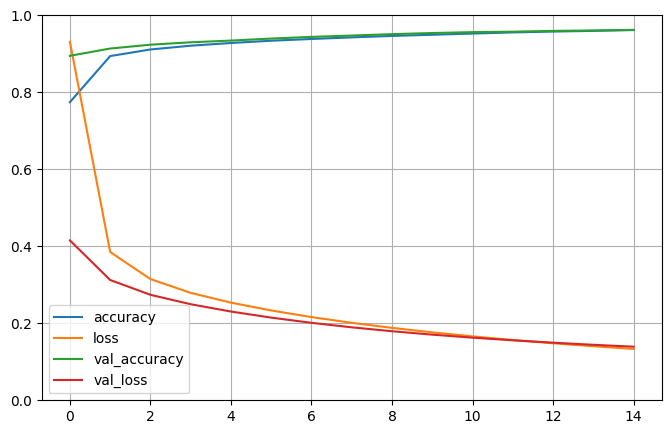

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

# Podemos ver cómo evoluciona el entrenamiento en función de las epochs
# Validación y training están muy cerca, no hay overfitting!
# Todavía no ha acabado de converger, ya que la loss en validación sigue bajando
pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1) # set the vertical range to [0-1]
plt.show()

Si el modelo no ha ido bien, prueba a cambiar el learning rate, cambia de optimizador y después prueba a cambiar capas, neuronas y funciones de activación.


***


### Evaluación con test


Ya tenemos el modelo entrenado. Probémoslo con test

In [35]:
# Obtenemos el "score" a partir del conjunto de test
# Evaluate the model on the test data using `evaluate`
print("Evaluate on test data")

# Método evaluate para que nos dé la loss y las métricas elegidas en el compile
results = model.evaluate(X_test, y_test)
print("test loss, test acc:", results)

Evaluate on test data
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9659 - loss: 0.1147
test loss, test acc: [0.0981718897819519, 0.9706000089645386]


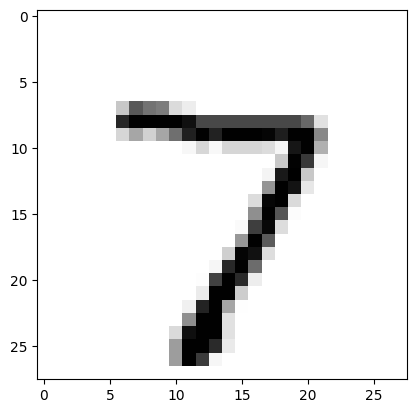

In [36]:
# Cogemos el primero
plt.imshow(X_test[0], cmap='Greys');

In [37]:
'''
Ojo: usamos slicing ([:1]) porque predict espera un conjunto de instancias, no una sola.
Nos da la probabilidad de pertenecer a cada clase.
'''
predictions = model.predict(X_test[:1]).round(3)
print("predictions shape:", predictions.shape)
print(predictions[0])
print(np.argmax(predictions[0]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step
predictions shape: (1, 10)
[0.    0.    0.    0.002 0.    0.    0.    0.998 0.    0.   ]
7


In [38]:
predictions.max()

0.998

In [39]:
predictions.argmax()

7

In [40]:
y_pred = model.predict(X_test).argmax(axis=1) # La clase con mayor probabilidad para cada imagen
y_pred[0:5]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


array([7, 2, 1, 0, 4], dtype=int64)

In [41]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.97      0.98      0.98       980
         1.0       0.98      0.99      0.98      1135
         2.0       0.98      0.97      0.97      1032
         3.0       0.96      0.98      0.97      1010
         4.0       0.97      0.97      0.97       982
         5.0       0.97      0.96      0.97       892
         6.0       0.96      0.98      0.97       958
         7.0       0.96      0.97      0.97      1028
         8.0       0.98      0.94      0.96       974
         9.0       0.97      0.96      0.97      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



***

### Problema de regresión
Veamos cómo aplicar una red neuronal con Keras a un problema de regresión.

In [42]:
# Cargamos datos
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()
df = pd.DataFrame(housing.data, columns = housing.feature_names)
df['target'] = housing['target']
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Dividimos en train, test y validation

In [43]:
X_train_full, X_test, y_train_full, y_test = train_test_split(housing.data,
                                                              housing.target,
                                                              random_state=42)

X_train, X_valid, y_train, y_valid = train_test_split(X_train_full,
                                                      y_train_full,
                                                      random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)
X_test = scaler.transform(X_test)

In [44]:
X_train.shape

(11610, 8)

Montamos el modelo: una única capa oculta de 30 neuronas, precedida de la entrada con las 8 features.

Se trata de un modelo de regresión, por lo que la capa de salida es una única neurona.
     
Vamos a configurar una red como esta:  
<img src="./img/mlp_regresion.png" alt="drawing" width="300"/>

In [45]:
model = keras.models.Sequential([
    keras.Input(shape=X_train.shape[1:]), # 8 features
    # No hace falta capa de flatten. No hay que aplanar ninguna imagen
    keras.layers.Dense(30, activation="relu"),
    keras.layers.Dense(1) # una única neurona de salida
    # Sin función de activación. ReLU no iría mal si el output es positivo. Sigmoide si está acotado entre 0 y 1.
])

model.compile(loss="mean_squared_error",
              optimizer="sgd",
              metrics = ["RootMeanSquaredError"])

history = model.fit(X_train, y_train, epochs=20,
                    validation_data=(X_valid, y_valid))

mse_test = model.evaluate(X_test, y_test)
X_new = X_test[:3] # pretend these are new instances
y_pred = model.predict(X_new)

Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - RootMeanSquaredError: 1.1136 - loss: 1.3411 - val_RootMeanSquaredError: 2.2081 - val_loss: 4.8755
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - RootMeanSquaredError: 0.7003 - loss: 0.4910 - val_RootMeanSquaredError: 4.1304 - val_loss: 17.0606
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - RootMeanSquaredError: 0.7026 - loss: 0.4945 - val_RootMeanSquaredError: 3.6751 - val_loss: 13.5061
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - RootMeanSquaredError: 0.6969 - loss: 0.4866 - val_RootMeanSquaredError: 0.6227 - val_loss: 0.3877
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - RootMeanSquaredError: 0.6524 - loss: 0.4260 - val_RootMeanSquaredError: 0.6075 - val_loss: 0.3690
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - RootMeanSquaredError: 0.6415 - loss: 0.4119 - val_RootMeanSquaredError: 0.6014 - val_loss: 0.3616
Epoch 7/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - RootMeanSquaredError: 0.6351 - l

In [46]:
print("Test MSE, RMSE:", mse_test)

Test MSE, RMSE: [0.3526977002620697, 0.5938835740089417]


In [47]:
history.history

{'RootMeanSquaredError': [0.8696427941322327,
  0.7097207903862,
  0.7245428562164307,
  0.7053065299987793,
  0.6378927826881409,
  0.628454864025116,
  0.6228136420249939,
  0.6187280416488647,
  0.6153751611709595,
  0.6127320528030396,
  0.6100899577140808,
  0.6078377962112427,
  0.6055728197097778,
  0.6035059690475464,
  0.6016339659690857,
  0.599817156791687,
  0.5979212522506714,
  0.5962048768997192,
  0.5947011709213257,
  0.5931907296180725],
 'loss': [0.7562785744667053,
  0.5037035942077637,
  0.5249623656272888,
  0.4974573254585266,
  0.40690723061561584,
  0.39495551586151123,
  0.3878968060016632,
  0.3828243613243103,
  0.3786865770816803,
  0.3754405379295349,
  0.37220972776412964,
  0.36946678161621094,
  0.36671844124794006,
  0.36421945691108704,
  0.3619634509086609,
  0.35978060960769653,
  0.3575098514556885,
  0.3554602563381195,
  0.3536694645881653,
  0.3518752455711365],
 'val_RootMeanSquaredError': [2.2080562114715576,
  4.130447864532471,
  3.675066947

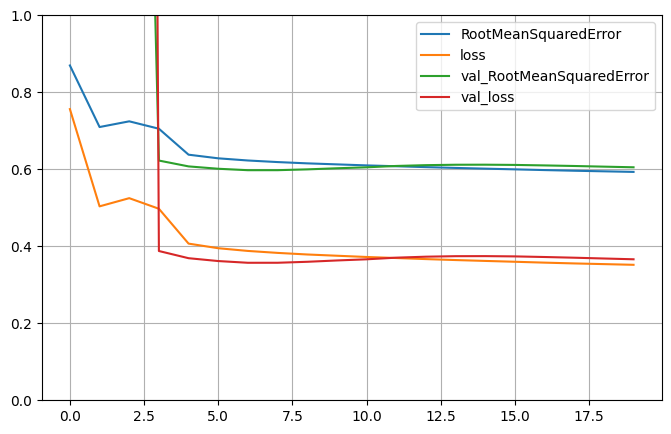

In [48]:
pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1) # set the vertical range to [0-1]
plt.show()

***

In [49]:
# Otra forma pure-Keras: el escalado lo hace una capa de la propia red
X_train_full, X_test, y_train_full, y_test = train_test_split(housing.data,
                                                              housing.target,
                                                              random_state=42)

X_train, X_valid, y_train, y_valid = train_test_split(X_train_full,
                                                      y_train_full,
                                                      random_state=42)


norm_layer = keras.layers.Normalization() # Es una Standardization
model = keras.models.Sequential([
    keras.Input(shape=X_train.shape[1:]),
    norm_layer,
    keras.layers.Dense(30, activation="relu"),
    keras.layers.Dense(1) # una única neurona de salida
])
optimizer = keras.optimizers.SGD()
model.compile(loss="mean_squared_error",
              optimizer=optimizer, metrics = ["RootMeanSquaredError","MeanAbsoluteError"])
norm_layer.adapt(X_train) # Calcula media y desviación típica con el train (como el fit del StandardScaler)
history = model.fit(X_train, y_train, epochs=20,
                    validation_data=(X_valid, y_valid))

mse_test = model.evaluate(X_test, y_test)
X_new = X_test[:3] # pretend these are new instances
y_pred = model.predict(X_new)

Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - MeanAbsoluteError: 0.8155 - RootMeanSquaredError: 1.1412 - loss: 1.3568 - val_MeanAbsoluteError: 0.6241 - val_RootMeanSquaredError: 4.4018 - val_loss: 19.3755
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - MeanAbsoluteError: 0.5322 - RootMeanSquaredError: 0.7616 - loss: 0.5809 - val_MeanAbsoluteError: 0.5722 - val_RootMeanSquaredError: 4.1670 - val_loss: 17.3641
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - MeanAbsoluteError: 0.4965 - RootMeanSquaredError: 0.7168 - loss: 0.5145 - val_MeanAbsoluteError: 0.4556 - val_RootMeanSquaredError: 0.6485 - val_loss: 0.4206
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - MeanAbsoluteError: 0.4809 - RootMeanSquaredError: 0.6747 - loss: 0.4557 - val_MeanAbsoluteError: 0.4430 - val_RootMeanSquaredError: 0.6401 - val_loss: 0.4097
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - MeanAbsoluteError: 0.4697 - RootMeanSquaredError: 0.6607 - loss: 0.4368 - val_MeanAbsoluteError:

In [50]:
print("Test MSE, RMSE, MAE:", mse_test)

Test MSE, RMSE, MAE: [0.3507699966430664, 0.5922583937644958, 0.41628190875053406]


Nueva capa al toolbox:

Funcionales:  
__Normalization__: keras.layers.Normalization -> Nos hace la estandarización de la entrada 
Hay que ejecutar el método `adapt` antes de llamar al fit del modelo que incluya la capa

***

### Guardar modelo
Para guardar el modelo usamos el formato nativo de Keras: un único fichero con extensión `.keras` que contiene la arquitectura, los pesos y la configuración del compile.

In [51]:
model.save("my_keras_model.keras")

In [52]:
# Lo volvemos a cargar
model = keras.models.load_model("my_keras_model.keras")

Otra opción es **exportar** el modelo en formato *SavedModel* de TensorFlow, pensado para el despliegue (TensorFlow Serving, TFLite...). Crea un directorio con varios ficheros (ojo, que habría que llevar a producción todo el directorio). Este formato sólo sirve para hacer inferencia, no para seguir entrenando con Keras.

In [53]:
model.export("my_model_savedmodel")

INFO:tensorflow:Assets written to: my_model_savedmodel\assets


Saved artifact at 'my_model_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 8), dtype=tf.float32, name='input_layer_4')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2053718765264: TensorSpec(shape=(1, 8), dtype=tf.float32, name=None)
  2053718764496: TensorSpec(shape=(1, 8), dtype=tf.float32, name=None)
  2053599815312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2053599812432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2053718761424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2053718765456: TensorSpec(shape=(), dtype=tf.resource, name=None)


### Callbacks
Son objetos que Keras ejecuta en determinados momentos del entrenamiento (por ejemplo, al final de cada epoch).
Por ejemplo, `ModelCheckpoint` sirve para que el modelo se vaya guardando tras cada epoch. Así no perdemos el progreso en caso de que decidamos interrumpir el entrenamiento. El callback recibe como argumento el nombre del fichero (`.keras`) donde queremos que se guarde el modelo entrenado. Con `save_best_only=True` sólo guarda cuando mejora la métrica de validación.

In [54]:
checkpoint_cb = keras.callbacks.ModelCheckpoint("callback_model.keras", save_best_only=True)
history = model.fit(X_train, y_train, epochs=10,
                    validation_data=(X_valid, y_valid),
                    callbacks=[checkpoint_cb])

Epoch 1/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - MeanAbsoluteError: 0.4301 - RootMeanSquaredError: 0.6054 - loss: 0.3667 - val_MeanAbsoluteError: 0.4116 - val_RootMeanSquaredError: 0.5993 - val_loss: 0.3592
Epoch 2/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - MeanAbsoluteError: 0.4288 - RootMeanSquaredError: 0.6041 - loss: 0.3651 - val_MeanAbsoluteError: 0.4106 - val_RootMeanSquaredError: 0.5968 - val_loss: 0.3562
Epoch 3/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - MeanAbsoluteError: 0.4276 - RootMeanSquaredError: 0.6026 - loss: 0.3633 - val_MeanAbsoluteError: 0.4094 - val_RootMeanSquaredError: 0.5940 - val_loss: 0.3528
Epoch 4/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - MeanAbsoluteError: 0.4265 - RootMeanSquaredError: 0.6012 - loss: 0.3616 - val_MeanAbsoluteError: 0.4094 - val_RootMeanSquaredError: 0.6018 - val_loss: 0.3622
Epoch 5/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - MeanAbsoluteError: 0.4254 - RootMeanSquaredError: 0.6002 - loss: 0.3604 - val_MeanAbsoluteError: 0

### Early Stopping
Interrumpe el entrenamiento cuando la métrica monitorizada en validación (por defecto, `val_loss`) lleva un número de epochs, llamado `patience`, sin mejorar. Se puede combinar con el callback anterior. Con `restore_best_weights=True` al terminar se queda con los pesos de la mejor epoch.

In [55]:
'''
10 está bien. Lo ponemos a 5 para el ejemplo
¿Qué considera como dejar de mejorar? parámetros min_delta y baseline
'''
early_stopping_cb = keras.callbacks.EarlyStopping(patience=5,
                                                  restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=100,
                    validation_data=(X_valid, y_valid),
                    callbacks=[checkpoint_cb, early_stopping_cb])

Epoch 1/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - MeanAbsoluteError: 0.4205 - RootMeanSquaredError: 0.5960 - loss: 0.3553 - val_MeanAbsoluteError: 0.4065 - val_RootMeanSquaredError: 0.6167 - val_loss: 0.3803
Epoch 2/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - MeanAbsoluteError: 0.4205 - RootMeanSquaredError: 0.5988 - loss: 0.3587 - val_MeanAbsoluteError: 0.4061 - val_RootMeanSquaredError: 0.6171 - val_loss: 0.3809
Epoch 3/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - MeanAbsoluteError: 0.4199 - RootMeanSquaredError: 0.5993 - loss: 0.3592 - val_MeanAbsoluteError: 0.4057 - val_RootMeanSquaredError: 0.6147 - val_loss: 0.3778
Epoch 4/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - MeanAbsoluteError: 0.4183 - RootMeanSquaredError: 0.5929 - loss: 0.3517 - val_MeanAbsoluteError: 0.4052 - val_RootMeanSquaredError: 0.6126 - val_loss: 0.3753
Epoch 5/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - MeanAbsoluteError: 0.4173 - RootMeanSquaredError: 0.5917 - loss: 0.3503 - val_MeanAbsoluteErr

***

## Hiperparámetros y tuning

Guía "casera":

1- Recetas (adaptadas de "Hands-on...")  PARA MLPs!!!!    
    * Capas:   
        - Empezar con una capa oculta e ir añadiendo  
        - Si pocas features -> más neuronas  (aumentar la combinación de features) (num_features < 100) [Orientativo]  
        - Si muchas features  -> menos neuronas (proyección tipo PCA) (num_features > 1000) [Orientativo] e ir aumentando en capas sucesivas
        - O empezar con muchas (doble de tus features e ir "estrechando los pantalones")  
        - Construcción en prisma o pirámide (para empezar)  
        - Inicialización: Empezar con Glorot, cambiar a He  
        - Activación: ReLU salvo la última, si muchas capas probar -> Swish, o SELU (ésta con el inicializador LeCun)   
    * Optimizadores:   
        - Si muchos datos*features -> Adam o AdamW con sus valores por defecto  
        - Si no, SGD con Nesterov activado, y momento a 0.9  
        - Learning rate -> 0.001-0.0001 para empezar e ir creciendo (learning-rate warm-up) (Si te atreves, buscar adaptive learning rate y optimizar con esto)  
    * Entrenamiento:  
        - Epochs: probar primero con pocas para ver cuánto tarda -> después, muchas epochs con el callback de EarlyStopping  
        - Batch size -> 32; si tienes muchos datos y una GPU a mano, puedes subirlo (64, 128, 256...)
    * Regularización (lo veremos):  
        - Dropout al 0.25-0.5 (sin SELU)



2- Pasos  
    - Si overfitting -> Regularizar: Earlystopping, Dropout (lo veremos en las siguientes unidades)  
    - Si underfitting -> Aumentar epochs, aumentar capacidad (más neuronas/capas), revisar el learning rate  
    - Jugar con optimizador: learning rate (de pequeño a grande), tipo de optimizador   
    - Jugar con número de capas (ojo al overfitting) y las funciones de activación y la inicialización de pesos  
    - Jugar con el número de neuronas por capa (suele ser pirámide o prisma, pero puedes jugar a expandir dimensiones)  
    - Combinar los dos anteriores  

3- Keras Tuner:
    https://keras.io/guides/keras_tuner/